# Homework 4: Building and applying a classification model

## Part 1: Model construction

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# import the wine dataset
from sklearn.datasets import load_wine
# import the MLPClassifier class from sklearn
from sklearn.neural_network import MLPClassifier
# import the scaler used to standardize the features
from sklearn.preprocessing import StandardScaler
# import metrics model to check the accuracy
from sklearn import metrics
# import train-test-split function from sklearn
from sklearn.model_selection import train_test_split

In [2]:
# load in the wine data
wine = load_wine()
# data, target_names, target, feature_names
print(wine.target_names)
print(wine.feature_names)

['class_0' 'class_1' 'class_2']
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


In [3]:
# Feature matrix (inputs) in an object named X
X = wine.data
# Response vector (output or target) in an object named y
y = wine.target

print(np.shape(X))
print(np.shape(y))

(178, 13)
(178,)


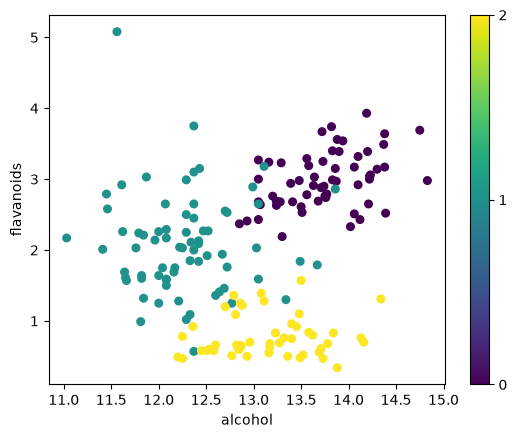

In [4]:
# take a first look at the data, color-coded by wine class
plt.scatter(wine.data[:,0], wine.data[:,6], s = 30, c = wine.target)
plt.colorbar(ticks=[0, 1, 2])
plt.ylabel(wine.feature_names[6])
plt.xlabel(wine.feature_names[0])
plt.show()

In [5]:
# Split wine data in train and test data (80:20)
# Set the random state to =4 to be reproducible.
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=4)

# check the shape of train and test objects
print(X_train.shape)
print(X_test.shape)

(142, 13)
(36, 13)


In [6]:
# The MLP is sensitive to the scale of the features, so standardize them.
# Fit the scaler on the training data only, then apply it to both train and test data.
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [7]:
# build the model based on the training data
model = MLPClassifier(hidden_layer_sizes=(10,), max_iter=3000, random_state=4)
model.fit(X_train_scaled, y_train)

# predict results from the test data using the model constructed above
y_pred = model.predict(X_test_scaled)

# compare the predicted result to the actual value to assess model performance
print("Accuracy score:", metrics.accuracy_score(y_test, y_pred))

Accuracy score: 0.9722222222222222


## Part 2: Explore hyperparameter space

In [8]:
# Try different numbers of neurons in one, two, and three hidden layers
# hidden_layer_sizes gives the number of neurons in each hidden layer
layer_options = [(5,), (10,), (15,), (20,), (30,), (50,),
                 (5, 5), (10, 10), (15, 15), (20, 20), (30, 30),
                 (10, 10, 10), (20, 20, 20), (30, 30, 30)]

# initialize empty list to save the accuracy score for each combination
scores = {}
scores_list = []

# iterate over the layer options to assess which model performs best
for layers in layer_options:

    # build the model based on the training data and the given layer sizes
    model = MLPClassifier(hidden_layer_sizes=layers, max_iter=3000, random_state=4)
    model.fit(X_train_scaled, y_train)

    # predict results from the test data using the model constructed in the previous step
    y_pred = model.predict(X_test_scaled)

    # compare the predicted result to the actual value to assess model performance
    scores[layers] = metrics.accuracy_score(y_test, y_pred)
    scores_list.append(scores[layers])
    print(layers, scores[layers])

(5,) 0.9722222222222222
(10,) 0.9722222222222222
(15,) 0.9722222222222222
(20,) 0.9722222222222222
(30,) 0.9722222222222222
(50,) 0.9722222222222222
(5, 5) 1.0
(10, 10) 0.9722222222222222
(15, 15) 0.9722222222222222
(20, 20) 0.9722222222222222
(30, 30) 0.9722222222222222
(10, 10, 10) 1.0
(20, 20, 20) 0.9722222222222222
(30, 30, 30) 1.0


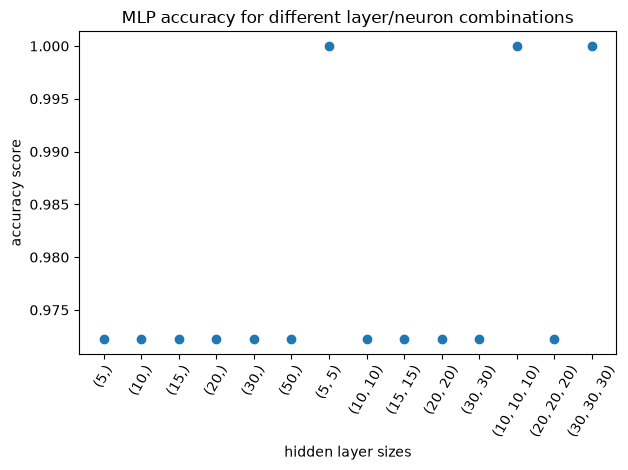

In [9]:
# plot the model accuracy for each layer/neuron combination
labels = [str(layers) for layers in layer_options]

plt.scatter(range(len(layer_options)), scores_list)
plt.xticks(range(len(layer_options)), labels, rotation=60)
plt.xlabel('hidden layer sizes')
plt.ylabel('accuracy score')
plt.title('MLP accuracy for different layer/neuron combinations')
plt.tight_layout()
plt.show()

In this run, (5, 5), (10, 10, 10), and (30, 30, 30) reach an accuracy score of 1.00 on the test data. Every other combination reaches 0.97, which on 36 test wines is a difference of a single wine. All combinations score above 0.9, so I would choose the simplest model that reaches the top score. That is (5, 5), because it matches the larger three layer networks with less neurons, which makes it faster to train and less likely to overfit. These scores come from one train-test split, so they do not guarantee the same accuracy on every new set of wines or data.

In [19]:
# For each combination with accuracy above 0.9, calculate the confusion matrix
# and the precision, recall, and f1-score for each target class
for layers in layer_options:
    if scores[layers] > 0.9:

        # rebuild the model for this combination and predict the test data
        model = MLPClassifier(hidden_layer_sizes=layers, max_iter=3000, random_state=4)
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)

        print("Hidden layer sizes:", layers)
        print("Accuracy score:", metrics.accuracy_score(y_test, y_pred))
        print("Confusion matrix:")
        print(metrics.confusion_matrix(y_test, y_pred))
        print(metrics.classification_report(y_test, y_pred, target_names=wine.target_names))
        print('-' * 60)

Hidden layer sizes: (5,)
Accuracy score: 0.9722222222222222
Confusion matrix:
[[10  0  0]
 [ 0 13  0]
 [ 0  1 12]]
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        10
     class_1       0.93      1.00      0.96        13
     class_2       1.00      0.92      0.96        13

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36

------------------------------------------------------------
Hidden layer sizes: (10,)
Accuracy score: 0.9722222222222222
Confusion matrix:
[[10  0  0]
 [ 0 13  0]
 [ 0  1 12]]
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        10
     class_1       0.93      1.00      0.96        13
     class_2       1.00      0.92      0.96        13

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
w

 In the confusion matrix, rows are the actual classes and columns are the predicted classes. Precision is how often a prediction of a class is correct, recall is how many wines of a class are found, and the f1-score combines the two.

class_0: precision, recall, and f1-score are 1.00 for every combination, so this class is never confused with another.
class_1 and class_2: the combinations that score 0.97 all make the same single error: one class_2 wine is predicted as class_1. This lowers recall for class_2 (0.92) and precision for class_1 (0.93). No other mistakes are made.
5, 5), (10, 10, 10), (30, 30, 30): these classify all 36 test wines correctly, so precision, recall, and f1-score are 1.00 for all three classes.

Because (5, 5), (10, 10, 10), and (30, 30, 30) perform identically for every class, there is no performance reason to prefer a bigger network. I will use (5, 5) in the final model because it is the smallest of the three.

## Part 3: Apply the tuned model

In [11]:
# load in the unknown wine samples
# the file is in the 'data' folder of the class GitHub page, so look in a few likely places
import os
paths = ['unknown_wine.csv', 'data/unknown_wine.csv', '../data/unknown_wine.csv']

for path in paths:
    if os.path.exists(path):
        unknown_df = pd.read_csv(path)
        print("loaded", path)
        break
else:
    # file not found: show where the notebook is looking so the path can be fixed
    print("Could not find unknown_wine.csv. The notebook is running in:", os.getcwd())
    print("Files here:", os.listdir('.'))

# check the size of the unknown data
print(unknown_df.shape)
unknown_df.head()

loaded unknown_wine.csv
(178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.20,1.75,2.44,15.3,115.3,3.17,3.35,0.33,2.05,6.52,1.04,3.09,1363.0,0
1,13.46,3.45,2.17,18.4,89.8,2.47,2.67,0.27,1.54,4.50,0.95,2.99,1089.5,0
2,13.74,1.79,2.57,15.6,111.8,3.34,3.33,0.31,1.65,7.16,1.15,3.06,1243.6,0
3,14.24,3.68,2.43,17.9,109.5,2.91,2.82,0.30,1.54,5.54,0.92,3.28,1152.1,0
4,13.82,1.63,2.26,16.9,98.6,2.43,2.59,0.27,1.69,5.00,1.09,2.97,1179.1,0


In [12]:
# the model needs the same 13 features, in the same order, as the wine data
X_unknown = unknown_df[wine.feature_names]

# check that there is one row per unknown wine and no missing values
print(X_unknown.shape)
print(X_unknown.isna().sum().sum())

(178, 13)
0


In [13]:
# Build the final model using the layers/neurons chosen in Part 2.
# As in the iris example, the final model is built on ALL of the labeled data
# (i.e. not just the training set), so we standardize using all of the wine data.
scaler_final = StandardScaler()
X_scaled = scaler_final.fit_transform(X)

final_model = MLPClassifier(hidden_layer_sizes=(5, 5), max_iter=3000, random_state=4)
final_model.fit(X_scaled, y)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(5, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",3000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",4
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [14]:
# apply the same scaling to the unknown wines, then predict
X_unknown_scaled = scaler_final.transform(X_unknown.values)

# predicted class for each unknown wine
y_predict = final_model.predict(X_unknown_scaled)

# predict_proba gives the probability that each wine belongs to each of the three classes
y_proba = final_model.predict_proba(X_unknown_scaled)

print(y_predict)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]


In [15]:
# list the probability of each class for each unknown wine
proba_df = pd.DataFrame(np.round(y_proba, 3),
                        columns = ['P(' + name + ')' for name in wine.target_names])
proba_df['predicted class'] = [wine.target_names[i] for i in y_predict]
proba_df.index.name = 'unknown wine'

# show every row
pd.set_option('display.max_rows', None)
proba_df

,P(class_0),P(class_1),P(class_2),predicted class
unknown wine,,,,
0,1.000,0.000,0.000,class_0
1,0.998,0.001,0.001,class_0
2,1.000,0.000,0.000,class_0
3,1.000,0.000,0.000,class_0
4,1.000,0.000,0.000,class_0
5,0.995,0.005,0.000,class_0
6,0.999,0.001,0.000,class_0
7,1.000,0.000,0.000,class_0
8,1.000,0.000,0.000,class_0


In [16]:
# summarize how confident the model 
max_proba = y_proba.max(axis = 1)   # the probability of the predicted class for each wine

print("number of unknown wines predicted in each class:")
print(proba_df['predicted class'].value_counts())
print()
print("wines where the predicted class has probability > 0.90:", (max_proba > 0.90).sum(), "of", len(max_proba))
print("lowest probability of any predicted class:", round(max_proba.min(), 3))

# the least certain predictions (predicted class has probability below 0.90)
proba_df[max_proba < 0.90]

number of unknown wines predicted in each class:
predicted class
class_1    71
class_0    59
class_2    48
Name: count, dtype: int64

wines where the predicted class has probability > 0.90: 175 of 178
lowest probability of any predicted class: 0.866


,P(class_0),P(class_1),P(class_2),predicted class
unknown wine,,,,
70,0.079,0.881,0.040,class_1
87,0.084,0.871,0.044,class_1
99,0.087,0.866,0.047,class_1


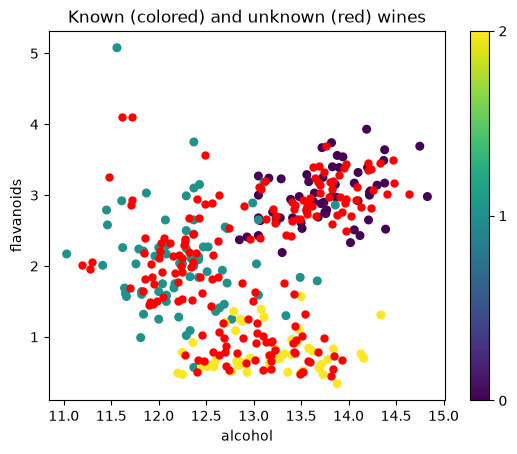

In [17]:
# plot the original wine data, color-coded by class, with the unknown wines on top
plt.scatter(wine.data[:,0], wine.data[:,6], s = 30, c = wine.target)
plt.colorbar(ticks=[0, 1, 2])
plt.plot(X_unknown.iloc[:,0], X_unknown.iloc[:,6], 'or', markersize = 5)
plt.ylabel(wine.feature_names[6])
plt.xlabel(wine.feature_names[0])
plt.title('Known (colored) and unknown (red) wines')
plt.show()

Comments on the results. predict_proba returns three probabilities for each wine that add up to 1, and the predicted class is the one with the highest probability. A wine with one probability close to 1 is a confident prediction; a wine whose top two probabilities are close together is borderline.

The summary above shows how many unknown wines were assigned to each class.
the predicted class has a probability above 0.90, so the model is confident about most of them.
The least certain wines (listed in the last table) are the ones where the probability is split between two classes. These are the predictions I would trust least and would want to check against other information about those wines.
In the scatter plot, the red unknown wines fall within or next to the clusters of known wines, which agrees with the predicted classes. Only two of the 13 features are plotted, so the plot cannot show everything the model uses.
The probabilities from a neural network can be overconfident, and the final model was fit on all labeled wines, so there is no held-out data to confirm these particular predictions. The test accuracy from Part 2 is the best estimate of how well the model works on new wines.